In [30]:

import pandas as pd
import numpy as np

# Load the three datasets
orders = pd.read_csv('/content/olist_orders_dataset.csv')
order_items = pd.read_csv('/content/olist_order_items_dataset.csv')
products = pd.read_csv('/content/olist_products_dataset.csv')

# Check the number of rows and columns
print("Orders:", orders.shape)
print("Order Items:", order_items.shape)
print("Products:", products.shape)


Orders: (99441, 8)
Order Items: (112650, 7)
Products: (32951, 9)


In [31]:

# Check missing values
for name, df in [
    ("Orders", orders),
    ("Order Items", order_items),
    ("Products", products)
]:
    print(f"\n===== {name} =====")

    print("\nMissing Values:")
    print(df.isnull().sum())

    print("\nDuplicate Rows:")
    print(df.duplicated().sum())

    print("\nData Types:")
    print(df.dtypes)



===== Orders =====

Missing Values:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Duplicate Rows:
0

Data Types:
order_id                         object
customer_id                      object
order_status                     object
order_purchase_timestamp         object
order_approved_at                object
order_delivered_carrier_date     object
order_delivered_customer_date    object
order_estimated_delivery_date    object
dtype: object

===== Order Items =====

Missing Values:
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

Duplicate Rows:
0

Data Types:
order_id          

In [32]:

# Count orders by status
print("Order Status Distribution:")
print(orders['order_status'].value_counts())

# Check which statuses have missing delivery dates
print("\nMissing Delivery Dates by Order Status:")
print(
    orders[orders['order_delivered_customer_date'].isna()]
    ['order_status'].value_counts()
)

# Check missing carrier dates by order status
print("\nMissing Carrier Dates by Order Status:")
print(
    orders[orders['order_delivered_carrier_date'].isna()]
    ['order_status'].value_counts()
)


Order Status Distribution:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Missing Delivery Dates by Order Status:
order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

Missing Carrier Dates by Order Status:
order_status
unavailable    609
canceled       550
invoiced       314
processing     301
created          5
approved         2
delivered        2
Name: count, dtype: int64


In [33]:

# Create working copies to preserve the original data
orders_clean = orders.copy()
order_items_clean = order_items.copy()
products_clean = products.copy()

# Convert order date columns to datetime
order_date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in order_date_columns:
    orders_clean[col] = pd.to_datetime(
        orders_clean[col], errors='coerce'
    )

# Convert shipping deadline to datetime
order_items_clean['shipping_limit_date'] = pd.to_datetime(
    order_items_clean['shipping_limit_date'],
    errors='coerce'
)

# Separate orders with valid delivery dates
delivered_orders = orders_clean[
    (orders_clean['order_status'] == 'delivered') &
    (orders_clean['order_delivered_customer_date'].notna())
].copy()

# Verify results
print("Order date types:")
print(orders_clean[order_date_columns].dtypes)

print("\nShipping deadline type:")
print(order_items_clean['shipping_limit_date'].dtype)

print("\nTotal orders:", len(orders_clean))
print("Delivered orders with valid dates:", len(delivered_orders))
print("Delivered orders missing delivery dates:",
      ((orders_clean['order_status'] == 'delivered') &
       orders_clean['order_delivered_customer_date'].isna()).sum())


Order date types:
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

Shipping deadline type:
datetime64[ns]

Total orders: 99441
Delivered orders with valid dates: 96470
Delivered orders missing delivery dates: 8


In [34]:

# Calculate actual delivery time in days
delivered_orders['delivery_time_days'] = (
    delivered_orders['order_delivered_customer_date'] -
    delivered_orders['order_purchase_timestamp']
).dt.total_seconds() / 86400

# Calculate delivery delay relative to the estimated date
delivered_orders['delivery_delay_days'] = (
    delivered_orders['order_delivered_customer_date'] -
    delivered_orders['order_estimated_delivery_date']
).dt.total_seconds() / 86400

# Check for invalid negative delivery durations
invalid_durations = (
    delivered_orders['delivery_time_days'] < 0
).sum()

print("Negative delivery durations:", invalid_durations)

# Calculate KPIs using valid delivery durations
valid_deliveries = delivered_orders[
    delivered_orders['delivery_time_days'] >= 0
].copy()

valid_deliveries['is_late'] = (
    valid_deliveries['delivery_delay_days'] > 0
)

average_delivery_time = valid_deliveries['delivery_time_days'].mean()

on_time_rate = (~valid_deliveries['is_late']).mean() * 100
late_rate = valid_deliveries['is_late'].mean() * 100

average_delay = valid_deliveries.loc[
    valid_deliveries['is_late'], 'delivery_delay_days'
].mean()

print("Valid deliveries:", len(valid_deliveries))
print(f"Average Delivery Time: {average_delivery_time:.2f} days")
print(f"On-Time Delivery Rate: {on_time_rate:.2f}%")
print(f"Late Delivery Rate: {late_rate:.2f}%")
print(f"Average Delay (Late Orders Only): {average_delay:.2f} days")


Negative delivery durations: 0
Valid deliveries: 96470
Average Delivery Time: 12.56 days
On-Time Delivery Rate: 91.89%
Late Delivery Rate: 8.11%
Average Delay (Late Orders Only): 9.55 days


In [35]:

# Compare delivery dates without the time of day
valid_deliveries['is_late'] = (
    valid_deliveries['order_delivered_customer_date'].dt.normalize()
    >
    valid_deliveries['order_estimated_delivery_date'].dt.normalize()
)

# Calculate calendar-day delivery delay
valid_deliveries['delay_calendar_days'] = (
    valid_deliveries['order_delivered_customer_date'].dt.normalize()
    -
    valid_deliveries['order_estimated_delivery_date'].dt.normalize()
).dt.days

# Recalculate delivery performance KPIs
on_time_rate = (~valid_deliveries['is_late']).mean() * 100
late_rate = valid_deliveries['is_late'].mean() * 100

average_delay = valid_deliveries.loc[
    valid_deliveries['is_late'],
    'delay_calendar_days'
].mean()

print("Valid Deliveries:", len(valid_deliveries))
print(f"Average Delivery Time: {average_delivery_time:.2f} days")
print(f"Corrected On-Time Delivery Rate: {on_time_rate:.2f}%")
print(f"Corrected Late Delivery Rate: {late_rate:.2f}%")
print(f"Average Delay (Late Orders Only): {average_delay:.2f} days")


Valid Deliveries: 96470
Average Delivery Time: 12.56 days
Corrected On-Time Delivery Rate: 93.23%
Corrected Late Delivery Rate: 6.77%
Average Delay (Late Orders Only): 10.62 days


In [36]:

# Extract the purchase month
valid_deliveries['purchase_month'] = (
    valid_deliveries['order_purchase_timestamp']
    .dt.to_period('M')
)

# Group deliveries by purchase month
monthly_performance = (
    valid_deliveries
    .groupby('purchase_month')
    .agg(
        total_deliveries=('order_id', 'count'),
        late_deliveries=('is_late', 'sum'),
        avg_delivery_days=('delivery_time_days', 'mean')
    )
    .reset_index()
)

# Calculate monthly late delivery percentage
monthly_performance['late_delivery_rate'] = (
    monthly_performance['late_deliveries']
    / monthly_performance['total_deliveries']
    * 100
)

# Display results
print(
    monthly_performance[
        ['purchase_month',
         'total_deliveries',
         'late_deliveries',
         'late_delivery_rate',
         'avg_delivery_days']
    ].round(2).to_string(index=False)
)


purchase_month  total_deliveries  late_deliveries  late_delivery_rate  avg_delivery_days
       2016-09                 1                1              100.00              54.81
       2016-10               265                2                0.75              19.60
       2016-12                 1                0                0.00               4.69
       2017-01               750               22                2.93              12.65
       2017-02              1653               49                2.96              13.17
       2017-03              2546              116                4.56              12.95
       2017-04              2303              151                6.56              14.92
       2017-05              3545              106                2.99              11.32
       2017-06              3135               95                3.03              12.01
       2017-07              3872              108                2.79              11.59
       2017-08       

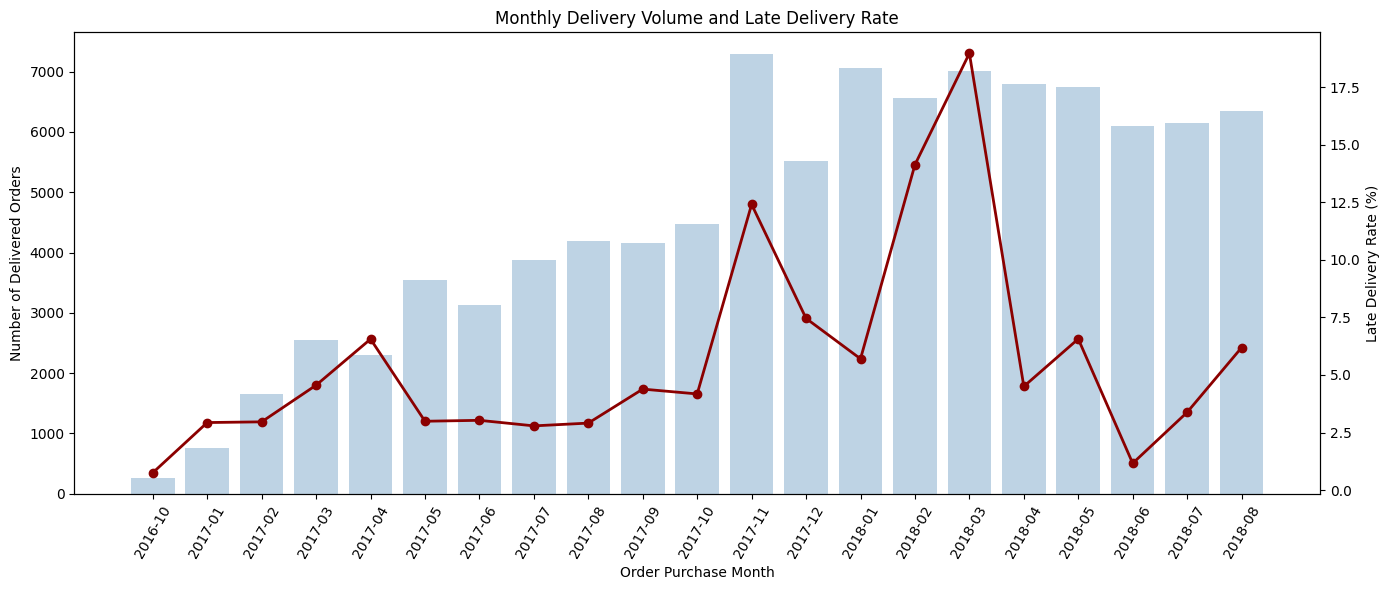

In [37]:

import matplotlib.pyplot as plt

# Focus on months with at least 100 delivered orders
monthly_chart = monthly_performance[
    monthly_performance['total_deliveries'] >= 100
].copy()

monthly_chart['month_label'] = (
    monthly_chart['purchase_month'].astype(str)
)

fig, ax1 = plt.subplots(figsize=(14, 6))

# Monthly delivery volume
ax1.bar(
    monthly_chart['month_label'],
    monthly_chart['total_deliveries'],
    color='steelblue',
    alpha=0.35,
    label='Delivered Orders'
)

ax1.set_ylabel('Number of Delivered Orders')
ax1.set_xlabel('Order Purchase Month')

# Monthly late delivery rate
ax2 = ax1.twinx()

ax2.plot(
    monthly_chart['month_label'],
    monthly_chart['late_delivery_rate'],
    color='darkred',
    marker='o',
    linewidth=2,
    label='Late Delivery Rate'
)

ax2.set_ylabel('Late Delivery Rate (%)')

plt.title('Monthly Delivery Volume and Late Delivery Rate')
ax1.tick_params(axis='x', rotation=60)

fig.tight_layout()

plt.savefig(
    'monthly_delivery_performance.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


In [38]:

# Calculate processing and transit times
valid_deliveries['processing_days'] = (
    valid_deliveries['order_delivered_carrier_date']
    - valid_deliveries['order_purchase_timestamp']
).dt.total_seconds() / 86400

valid_deliveries['transit_days'] = (
    valid_deliveries['order_delivered_customer_date']
    - valid_deliveries['order_delivered_carrier_date']
).dt.total_seconds() / 86400

# Identify missing and invalid stage durations
print("Missing processing times:",
      valid_deliveries['processing_days'].isna().sum())

print("Missing transit times:",
      valid_deliveries['transit_days'].isna().sum())

print("Negative processing times:",
      (valid_deliveries['processing_days'] < 0).sum())

print("Negative transit times:",
      (valid_deliveries['transit_days'] < 0).sum())

# Keep orders with valid durations for both stages
stage_analysis = valid_deliveries[
    valid_deliveries['processing_days'].ge(0)
    & valid_deliveries['transit_days'].ge(0)
].copy()

# Compare monthly averages
monthly_stages = (
    stage_analysis
    .groupby('purchase_month')
    .agg(
        orders=('order_id', 'count'),
        avg_processing_days=('processing_days', 'mean'),
        avg_transit_days=('transit_days', 'mean'),
        late_rate=('is_late', 'mean')
    )
    .reset_index()
)

monthly_stages['late_rate'] *= 100

# Display months with at least 100 orders
print(
    monthly_stages[
        monthly_stages['orders'] >= 100
    ].round(2).to_string(index=False)
)


Missing processing times: 1
Missing transit times: 1
Negative processing times: 165
Negative transit times: 23
purchase_month  orders  avg_processing_days  avg_transit_days  late_rate
       2016-10     261                13.81              5.87       0.77
       2017-01     749                 3.42              9.22       2.94
       2017-02    1651                 3.62              9.56       2.97
       2017-03    2545                 3.12              9.84       4.56
       2017-04    2303                 3.68             11.24       6.56
       2017-05    3544                 2.98              8.34       2.99
       2017-06    3134                 3.13              8.88       3.03
       2017-07    3861                 3.10              8.51       2.80
       2017-08    4191                 3.08              8.07       2.91
       2017-09    4149                 3.19              8.65       4.36
       2017-10    4478                 3.45              8.41       4.18
       2017-1

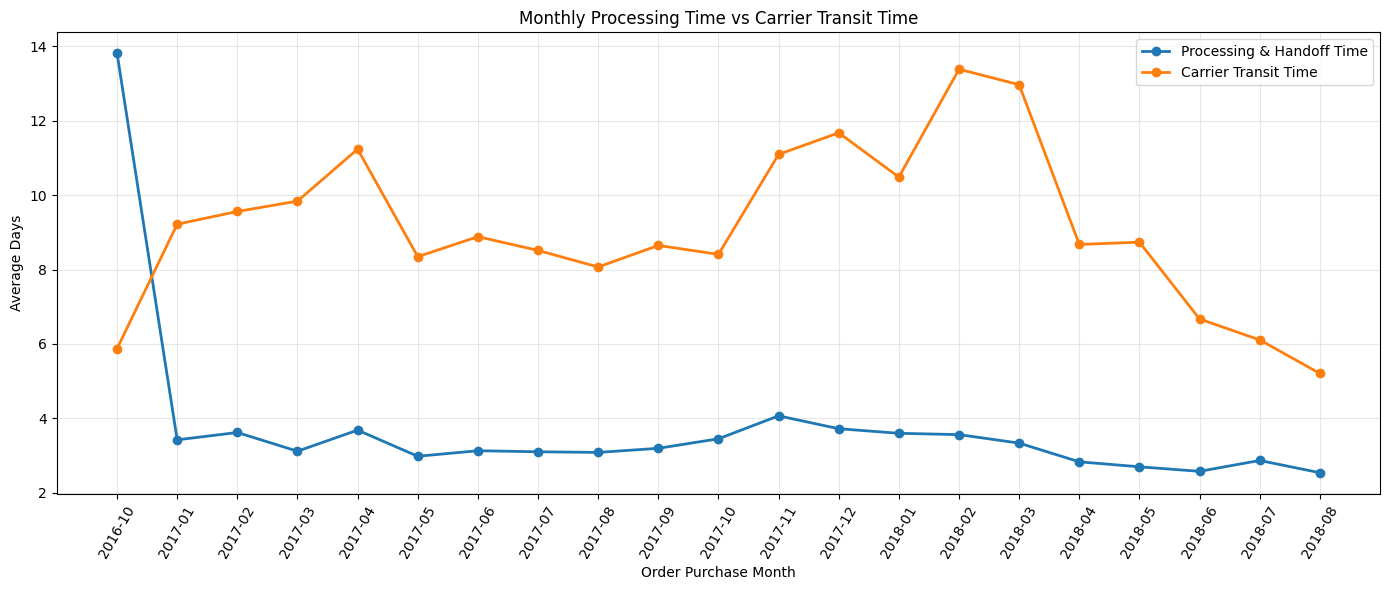

In [39]:

import matplotlib.pyplot as plt

# Keep months with at least 100 valid stage records
stage_chart = monthly_stages[
    monthly_stages['orders'] >= 100
].copy()

stage_chart['month_label'] = (
    stage_chart['purchase_month'].astype(str)
)

plt.figure(figsize=(14, 6))

plt.plot(
    stage_chart['month_label'],
    stage_chart['avg_processing_days'],
    marker='o',
    linewidth=2,
    label='Processing & Handoff Time'
)

plt.plot(
    stage_chart['month_label'],
    stage_chart['avg_transit_days'],
    marker='o',
    linewidth=2,
    label='Carrier Transit Time'
)

plt.title('Monthly Processing Time vs Carrier Transit Time')
plt.xlabel('Order Purchase Month')
plt.ylabel('Average Days')
plt.xticks(rotation=60)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    'processing_vs_transit_time.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


In [40]:

# Join order items with carrier handoff dates
shipping_analysis = order_items_clean.merge(
    orders_clean[
        ['order_id', 'order_status',
         'order_delivered_carrier_date']
    ],
    on='order_id',
    how='left',
    validate='many_to_one'
)

# Keep items from orders with a recorded carrier handoff
shipping_analysis = shipping_analysis[
    shipping_analysis['order_delivered_carrier_date'].notna()
    & shipping_analysis['shipping_limit_date'].notna()
].copy()

# Calculate how many days after the deadline
shipping_analysis['handoff_delay_days'] = (
    shipping_analysis['order_delivered_carrier_date']
    - shipping_analysis['shipping_limit_date']
).dt.total_seconds() / 86400

# Compare calendar dates
shipping_analysis['late_handoff'] = (
    shipping_analysis['order_delivered_carrier_date'].dt.normalize()
    >
    shipping_analysis['shipping_limit_date'].dt.normalize()
)

# Calculate overall results
total_items = len(shipping_analysis)
late_items = shipping_analysis['late_handoff'].sum()

late_handoff_rate = (
    shipping_analysis['late_handoff'].mean() * 100
)

print("Order items with carrier handoff dates:", total_items)
print("Items with late carrier handoff:", late_items)
print(f"Late Handoff Rate: {late_handoff_rate:.2f}%")

print("\nLate Handoff by Order Status:")
print(
    shipping_analysis.groupby('order_status')['late_handoff']
    .agg(['count', 'sum', 'mean'])
    .round(3)
)


Order items with carrier handoff dates: 111456
Items with late carrier handoff: 6670
Late Handoff Rate: 5.98%

Late Handoff by Order Status:
               count   sum   mean
order_status                     
canceled          76     6  0.079
delivered     110195  6570  0.060
shipped         1185    94  0.079


In [41]:

# Calculate shipping performance for each seller
seller_performance = (
    shipping_analysis
    .groupby('seller_id')
    .agg(
        total_items=('order_id', 'count'),
        late_items=('late_handoff', 'sum'),
        avg_handoff_delay_days=('handoff_delay_days', 'mean')
    )
    .reset_index()
)

# Calculate late handoff percentage
seller_performance['late_handoff_rate'] = (
    seller_performance['late_items']
    / seller_performance['total_items']
    * 100
)

# Keep sellers with at least 30 order items
active_sellers = seller_performance[
    seller_performance['total_items'] >= 30
].copy()

# Rank sellers by late handoff rate
seller_ranking = active_sellers.sort_values(
    ['late_handoff_rate', 'total_items'],
    ascending=[False, False]
)

print("Total sellers analyzed:", len(seller_performance))
print("Sellers with at least 30 items:", len(active_sellers))

print("\nTop 10 Sellers with Highest Late Handoff Rates:")
print(
    seller_ranking[
        ['seller_id', 'total_items',
         'late_items', 'late_handoff_rate']
    ].head(10).round(2).to_string(index=False)
)

print("\nOverall Seller Late Handoff Rate:")
print(f"{shipping_analysis['late_handoff'].mean() * 100:.2f}%")


Total sellers analyzed: 2977
Sellers with at least 30 items: 684

Top 10 Sellers with Highest Late Handoff Rates:
                       seller_id  total_items  late_items  late_handoff_rate
48efc9d94a9834137efd9ea76b065a38           34          28              82.35
835f0f7810c76831d6c7d24c7a646d4d           48          34              70.83
1da366cade6d8276e7d8beea7af5d4bf           49          27              55.10
a7f13822ceb966b076af67121f87b063           86          46              53.49
54965bbe3e4f07ae045b90b0b8541f52           84          40              47.62
88460e8ebdecbfecb5f9601833981930          300         138              46.00
a49928bcdf77c55c6d6e05e09a9b4ca5          106          46              43.40
d71d863e5ef30d94e440c11be17dcd8f           30          13              43.33
8e6d7754bc7e0f22c96d255ebda59eba          130          56              43.08
0725b8c0f3f906e58f70cbe76b7c748c           36          15              41.67

Overall Seller Late Handoff Rate:
5.98

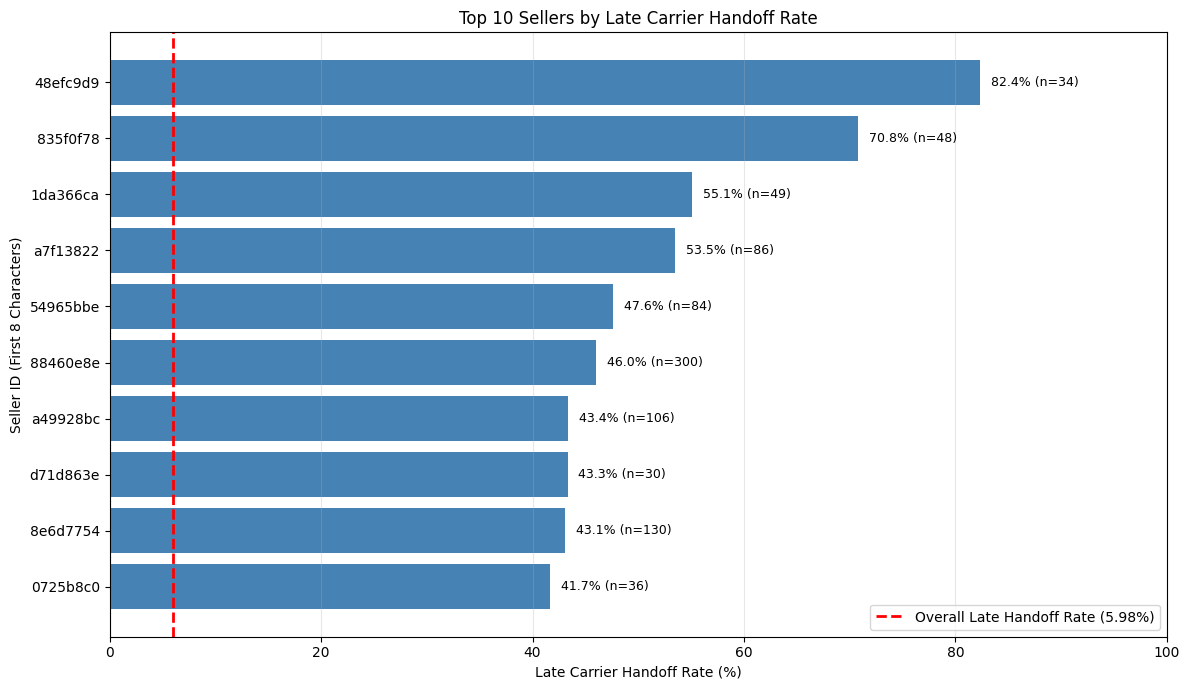

In [42]:

import matplotlib.pyplot as plt

# Select the 10 sellers with highest late-handoff rates
top_sellers = seller_ranking.head(10).copy()

# Shorten seller IDs for chart readability
top_sellers['seller_label'] = (
    top_sellers['seller_id'].str[:8]
)

# Sort for horizontal bar chart
top_sellers = top_sellers.sort_values(
    'late_handoff_rate',
    ascending=True
)

plt.figure(figsize=(12, 7))

bars = plt.barh(
    top_sellers['seller_label'],
    top_sellers['late_handoff_rate'],
    color='steelblue'
)

# Overall benchmark
plt.axvline(
    x=late_handoff_rate,
    color='red',
    linestyle='--',
    linewidth=2,
    label=f'Overall Late Handoff Rate ({late_handoff_rate:.2f}%)'
)

# Add percentage and volume labels
for bar, (_, seller) in zip(bars, top_sellers.iterrows()):
    plt.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{seller['late_handoff_rate']:.1f}% "
        f"(n={seller['total_items']})",
        va='center',
        fontsize=9
    )

plt.title('Top 10 Sellers by Late Carrier Handoff Rate')
plt.xlabel('Late Carrier Handoff Rate (%)')
plt.ylabel('Seller ID (First 8 Characters)')
plt.xlim(0, 100)
plt.legend()
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()

plt.savefig(
    'seller_late_handoff_performance.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


In [43]:

# Create an order-level shipping deadline
# For multi-item orders, use the latest item shipping deadline
order_deadlines = (
    order_items_clean
    .groupby('order_id', as_index=False)
    .agg(
        shipping_deadline=('shipping_limit_date', 'max')
    )
)

# Join deadlines to valid delivered orders
handoff_delivery = valid_deliveries.merge(
    order_deadlines,
    on='order_id',
    how='left',
    validate='one_to_one'
)

# Keep orders with required timestamps
handoff_delivery = handoff_delivery.dropna(
    subset=[
        'shipping_deadline',
        'order_delivered_carrier_date',
        'order_delivered_customer_date',
        'order_estimated_delivery_date'
    ]
).copy()

# Compare calendar dates for handoff compliance
handoff_delivery['late_handoff'] = (
    handoff_delivery['order_delivered_carrier_date'].dt.normalize()
    >
    handoff_delivery['shipping_deadline'].dt.normalize()
)

# Compare actual vs estimated customer delivery
handoff_delivery['late_customer_delivery'] = (
    handoff_delivery['order_delivered_customer_date'].dt.normalize()
    >
    handoff_delivery['order_estimated_delivery_date'].dt.normalize()
)

# Compare both groups
handoff_impact = (
    handoff_delivery
    .groupby('late_handoff')
    .agg(
        total_orders=('order_id', 'count'),
        late_customer_deliveries=('late_customer_delivery', 'sum'),
        late_delivery_rate=('late_customer_delivery', 'mean')
    )
    .reset_index()
)

handoff_impact['late_delivery_rate'] *= 100

handoff_impact['handoff_status'] = (
    handoff_impact['late_handoff'].map({
        False: 'On-Time Carrier Handoff',
        True: 'Late Carrier Handoff'
    })
)

print("Orders analyzed:", len(handoff_delivery))
print("\nCustomer Delivery Performance by Carrier Handoff Status:")

print(
    handoff_impact[
        [
            'handoff_status',
            'total_orders',
            'late_customer_deliveries',
            'late_delivery_rate'
        ]
    ].round(2).to_string(index=False)
)


Orders analyzed: 96469

Customer Delivery Performance by Carrier Handoff Status:
         handoff_status  total_orders  late_customer_deliveries  late_delivery_rate
On-Time Carrier Handoff         90899                      5073                5.58
   Late Carrier Handoff          5570                      1460               26.21


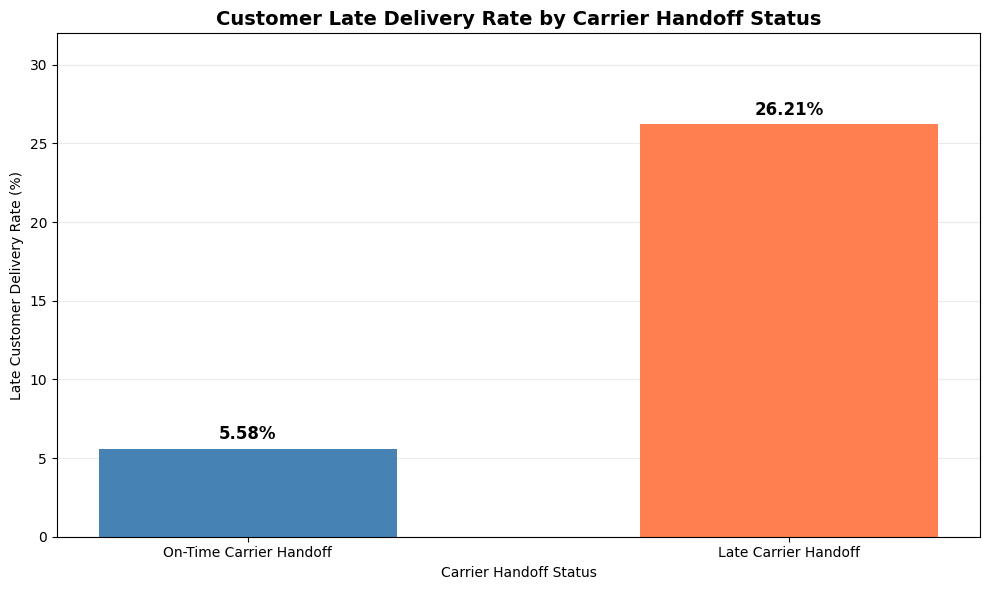

In [44]:

import matplotlib.pyplot as plt

# Prepare chart data
chart_data = handoff_impact.copy()

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    chart_data['handoff_status'],
    chart_data['late_delivery_rate'],
    color=['steelblue', 'coral'],
    width=0.55
)

# Add percentage labels above bars
for bar, rate in zip(
    bars,
    chart_data['late_delivery_rate']
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.6,
        f'{rate:.2f}%',
        ha='center',
        fontsize=12,
        fontweight='bold'
    )

ax.set_title(
    'Customer Late Delivery Rate by Carrier Handoff Status',
    fontsize=14,
    fontweight='bold'
)

ax.set_xlabel('Carrier Handoff Status')
ax.set_ylabel('Late Customer Delivery Rate (%)')
ax.set_ylim(0, 32)

ax.grid(axis='y', alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    'handoff_vs_customer_delivery.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


In [45]:

# STEP 22: Freight Cost Analysis

# Use the cleaned order items dataset
freight_analysis = order_items_clean.copy()

# Calculate freight as a percentage of product price
freight_analysis['freight_pct'] = (
    freight_analysis['freight_value']
    / freight_analysis['price'].replace(0, np.nan)
) * 100

# Calculate total item amount including freight
freight_analysis['total_item_amount'] = (
    freight_analysis['price']
    + freight_analysis['freight_value']
)

# Calculate key metrics
total_product_value = freight_analysis['price'].sum()
total_freight_value = freight_analysis['freight_value'].sum()

avg_freight = freight_analysis['freight_value'].mean()

overall_freight_ratio = (
    total_freight_value / total_product_value
) * 100

median_freight_pct = freight_analysis['freight_pct'].median()

# Display results
print("Total Order Items:", len(freight_analysis))

print(f"Total Product Value: R$ {total_product_value:,.2f}")
print(f"Total Freight Charges: R$ {total_freight_value:,.2f}")

print(f"Average Freight per Item: R$ {avg_freight:.2f}")

print(f"Overall Freight-to-Product Ratio: {overall_freight_ratio:.2f}%")

print(f"Median Item Freight Percentage: {median_freight_pct:.2f}%")

# Examine correlation
print(
    "\nCorrelation between Product Price and Freight:",
    round(
        freight_analysis['price'].corr(
            freight_analysis['freight_value']
        ), 3
    )
)


Total Order Items: 112650
Total Product Value: R$ 13,591,643.70
Total Freight Charges: R$ 2,251,909.54
Average Freight per Item: R$ 19.99
Overall Freight-to-Product Ratio: 16.57%
Median Item Freight Percentage: 23.14%

Correlation between Product Price and Freight: 0.414


In [46]:

# STEP 23: Freight Analysis by Product Category

# Join order items with product information
freight_categories = freight_analysis.merge(
    products_clean[
        ['product_id', 'product_category_name']
    ],
    on='product_id',
    how='left',
    validate='many_to_one'
)

# Replace missing category names
freight_categories['product_category_name'] = (
    freight_categories['product_category_name']
    .fillna('unknown')
)

# Calculate category-level metrics
category_freight = (
    freight_categories
    .groupby('product_category_name')
    .agg(
        total_items=('order_id', 'count'),
        total_product_value=('price', 'sum'),
        total_freight=('freight_value', 'sum'),
        avg_freight=('freight_value', 'mean')
    )
    .reset_index()
)

# Calculate freight-to-product ratio
category_freight['freight_ratio_pct'] = (
    category_freight['total_freight']
    / category_freight['total_product_value'].replace(0, np.nan)
) * 100

# Keep categories with at least 100 items
category_freight_filtered = category_freight[
    category_freight['total_items'] >= 100
].copy()

# Rank categories by freight ratio
category_freight_ranked = (
    category_freight_filtered
    .sort_values('freight_ratio_pct', ascending=False)
)

print("Categories analyzed:", len(category_freight))
print(
    "Categories with at least 100 items:",
    len(category_freight_filtered)
)

print("\nTop 15 Categories by Freight-to-Product Ratio:")

print(
    category_freight_ranked[
        [
            'product_category_name',
            'total_items',
            'avg_freight',
            'freight_ratio_pct'
        ]
    ].head(15).round(2).to_string(index=False)
)


Categories analyzed: 74
Categories with at least 100 items: 54

Top 15 Categories by Freight-to-Product Ratio:
                         product_category_name  total_items  avg_freight  freight_ratio_pct
                              artigos_de_natal          153        21.11              36.69
                       sinalizacao_e_seguranca          199        32.70              30.26
                             alimentos_bebidas          278        16.22              29.70
                                   eletronicos         2767        16.83              29.07
                                   moveis_sala          503        35.72              26.07
moveis_cozinha_area_de_servico_jantar_e_jardim          281        42.70              25.90
                                       bebidas          379        15.15              25.60
                             moveis_escritorio         1691        40.55              25.03
                                     alimentos          510  

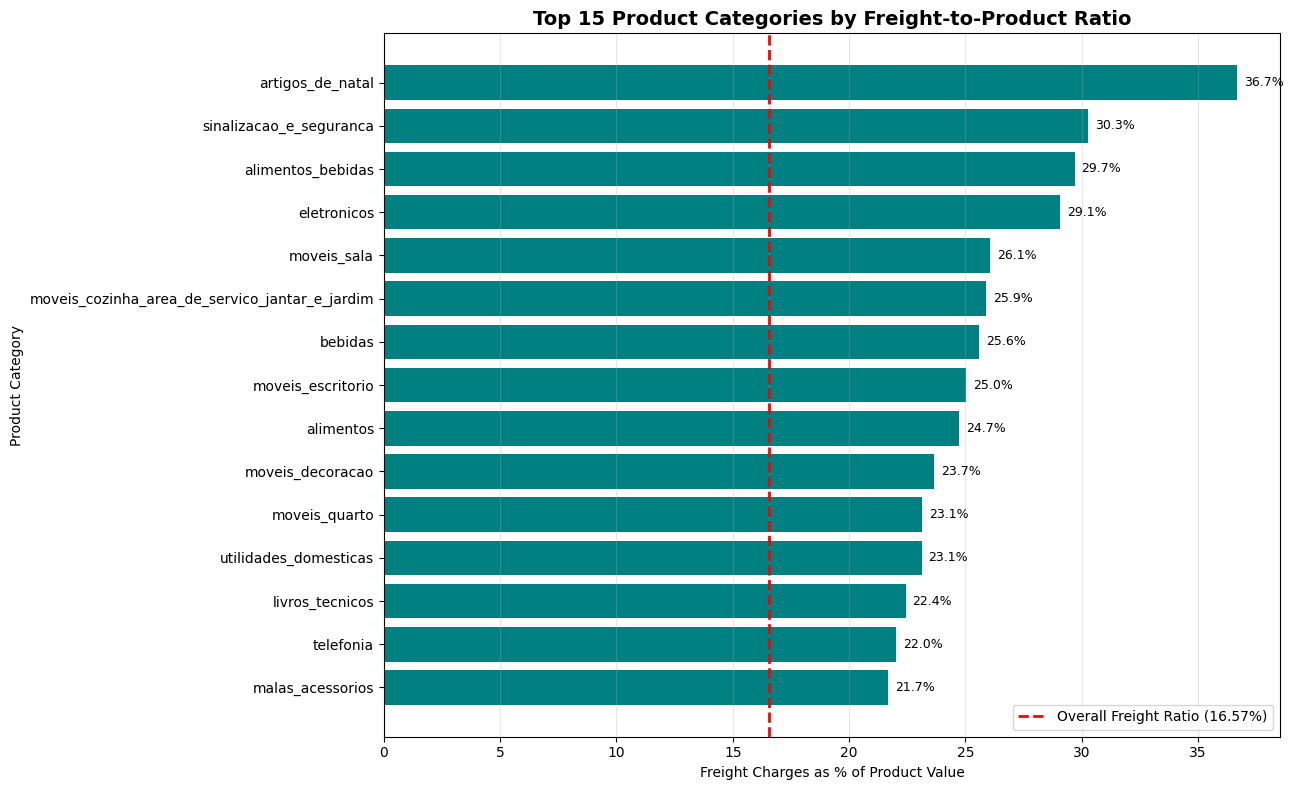

In [47]:

import matplotlib.pyplot as plt

# Select top 15 categories
top_freight_categories = (
    category_freight_ranked.head(15).copy()
)

# Sort for horizontal chart
top_freight_categories = (
    top_freight_categories.sort_values(
        'freight_ratio_pct',
        ascending=True
    )
)

plt.figure(figsize=(13, 8))

bars = plt.barh(
    top_freight_categories['product_category_name'],
    top_freight_categories['freight_ratio_pct'],
    color='teal'
)

# Add percentage labels
for bar, value in zip(
    bars,
    top_freight_categories['freight_ratio_pct']
):
    plt.text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f'{value:.1f}%',
        va='center',
        fontsize=9
    )

# Overall freight ratio benchmark
plt.axvline(
    overall_freight_ratio,
    color='red',
    linestyle='--',
    linewidth=2,
    label=f'Overall Freight Ratio ({overall_freight_ratio:.2f}%)'
)

plt.title(
    'Top 15 Product Categories by Freight-to-Product Ratio',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Freight Charges as % of Product Value')
plt.ylabel('Product Category')
plt.legend()
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()

plt.savefig(
    'freight_ratio_by_category.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


In [48]:

# STEP 25: Translate Product Categories to English

# Load the translation dataset
translations = pd.read_csv(
    '/content/product_category_name_translation.csv'
)

# Check the translation dataset
print("Translation Dataset Shape:", translations.shape)

print("\nAvailable Columns:")
print(translations.columns.tolist())

# Join English names to our category freight analysis
category_freight_english = category_freight_ranked.merge(
    translations,
    on='product_category_name',
    how='left',
    validate='one_to_one'
)

# Use original category name if translation is unavailable
category_freight_english['category_english'] = (
    category_freight_english[
        'product_category_name_english'
    ].fillna(
        category_freight_english['product_category_name']
    )
)

# Display top 15 categories in English
print("\nTop 15 Categories in English:")

print(
    category_freight_english[
        [
            'category_english',
            'total_items',
            'avg_freight',
            'freight_ratio_pct'
        ]
    ].head(15).round(2).to_string(index=False)
)


Translation Dataset Shape: (71, 2)

Available Columns:
['product_category_name', 'product_category_name_english']

Top 15 Categories in English:
                       category_english  total_items  avg_freight  freight_ratio_pct
                     christmas_supplies          153        21.11              36.69
                 signaling_and_security          199        32.70              30.26
                             food_drink          278        16.22              29.70
                            electronics         2767        16.83              29.07
                  furniture_living_room          503        35.72              26.07
kitchen_dining_laundry_garden_furniture          281        42.70              25.90
                                 drinks          379        15.15              25.60
                       office_furniture         1691        40.55              25.03
                                   food          510        14.26              24.74
     

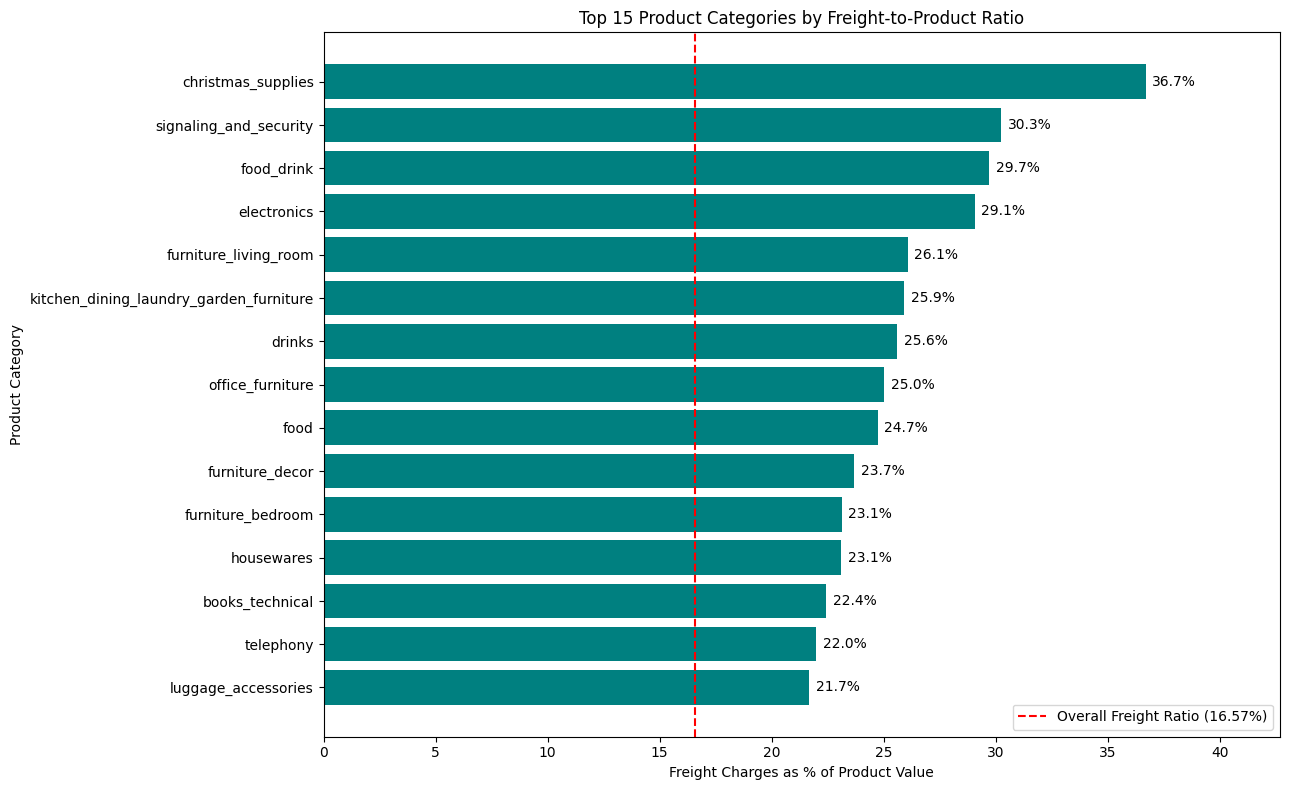

In [49]:

import matplotlib.pyplot as plt

# Select the top 15 categories
top_15_english = category_freight_english.head(15).copy()

# Create the chart
plt.figure(figsize=(13, 8))

bars = plt.barh(
    top_15_english['category_english'],
    top_15_english['freight_ratio_pct'],
    color='teal'
)

# Highest ratio at the top
plt.gca().invert_yaxis()

# Add percentage labels
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f'{width:.1f}%',
        va='center'
    )

# Overall freight ratio reference
plt.axvline(
    x=16.57,
    color='red',
    linestyle='--',
    label='Overall Freight Ratio (16.57%)'
)

plt.title('Top 15 Product Categories by Freight-to-Product Ratio')
plt.xlabel('Freight Charges as % of Product Value')
plt.ylabel('Product Category')
plt.legend()
plt.xlim(0, top_15_english['freight_ratio_pct'].max() + 6)
plt.tight_layout()

plt.show()


In [50]:

# STEP 27: Product Weight vs Freight Charges

# Join order items with product weight
weight_freight = order_items.merge(
    products[['product_id', 'product_weight_g']],
    on='product_id',
    how='left',
    validate='many_to_one'
)

# Remove rows missing weight or freight information
weight_freight = weight_freight.dropna(
    subset=['product_weight_g', 'freight_value']
).copy()

# Convert weight from grams to kilograms
weight_freight['weight_kg'] = (
    weight_freight['product_weight_g'] / 1000
)

# Calculate correlation
weight_freight_corr = weight_freight[
    ['weight_kg', 'freight_value']
].corr().iloc[0, 1]

print("Order Items Analyzed:", len(weight_freight))
print("Average Product Weight (kg):",
      round(weight_freight['weight_kg'].mean(), 2))
print("Average Freight Charge (R$):",
      round(weight_freight['freight_value'].mean(), 2))
print("Correlation Between Weight and Freight:",
      round(weight_freight_corr, 3))


Order Items Analyzed: 112632
Average Product Weight (kg): 2.09
Average Freight Charge (R$): 19.99
Correlation Between Weight and Freight: 0.61


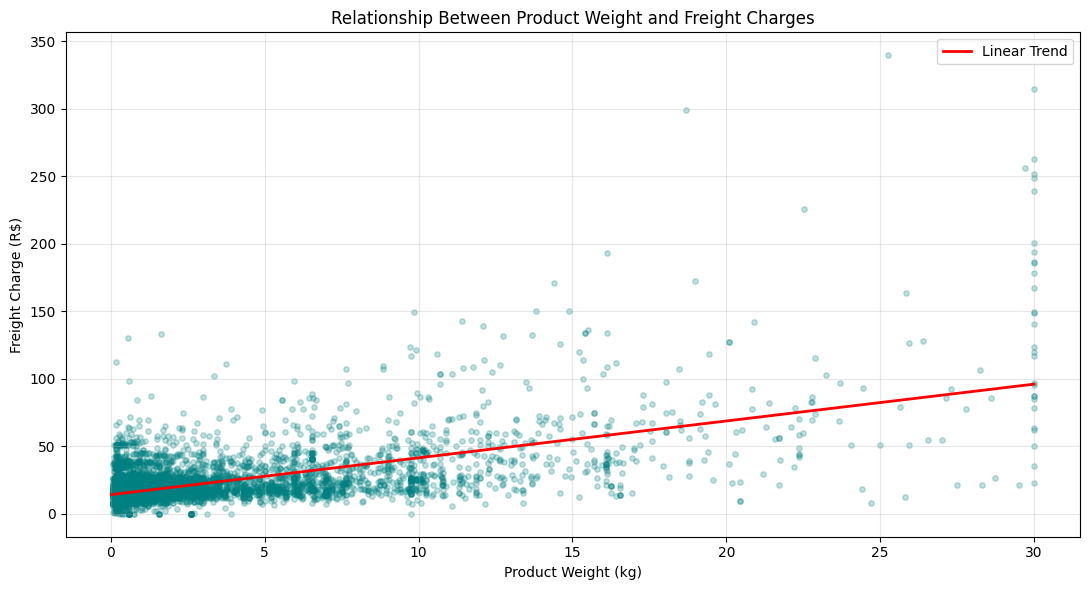

In [51]:

# STEP 28: Product Weight vs Freight Charges

import matplotlib.pyplot as plt
import numpy as np

# Use a sample for a clearer visualization
plot_data = weight_freight.sample(
    n=min(10000, len(weight_freight)),
    random_state=42
)

plt.figure(figsize=(11, 6))

plt.scatter(
    plot_data['weight_kg'],
    plot_data['freight_value'],
    alpha=0.25,
    color='teal',
    s=15
)

# Add a linear trend line
x = plot_data['weight_kg'].to_numpy()
y = plot_data['freight_value'].to_numpy()

slope, intercept = np.polyfit(x, y, 1)

x_line = np.linspace(x.min(), x.max(), 100)
y_line = slope * x_line + intercept

plt.plot(
    x_line,
    y_line,
    color='red',
    linewidth=2,
    label='Linear Trend'
)

plt.title('Relationship Between Product Weight and Freight Charges')
plt.xlabel('Product Weight (kg)')
plt.ylabel('Freight Charge (R$)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [52]:

# STEP 29: Freight Analysis by Product Weight Group

import pandas as pd

# Create weight categories
weight_freight['weight_group'] = pd.cut(
    weight_freight['weight_kg'],
    bins=[-0.001, 1, 5, 10, 20, float('inf')],
    labels=[
        '0-1 kg',
        '1-5 kg',
        '5-10 kg',
        '10-20 kg',
        'Above 20 kg'
    ]
)

# Calculate freight statistics for each group
weight_group_analysis = (
    weight_freight
    .groupby('weight_group', observed=True)
    .agg(
        total_items=('freight_value', 'size'),
        avg_freight=('freight_value', 'mean'),
        total_freight=('freight_value', 'sum'),
        avg_weight=('weight_kg', 'mean')
    )
    .reset_index()
)

# Round results
weight_group_analysis[
    ['avg_freight', 'total_freight', 'avg_weight']
] = weight_group_analysis[
    ['avg_freight', 'total_freight', 'avg_weight']
].round(2)

print("Freight Analysis by Product Weight Group:")
print(weight_group_analysis.to_string(index=False))


Freight Analysis by Product Weight Group:
weight_group  total_items  avg_freight  total_freight  avg_weight
      0-1 kg        67980        15.81     1074874.02        0.41
      1-5 kg        30760        20.28      623740.11        2.06
     5-10 kg         8596        30.68      263757.77        7.21
    10-20 kg         4388        47.48      208342.43       13.55
 Above 20 kg          908        89.12       80919.97       25.50


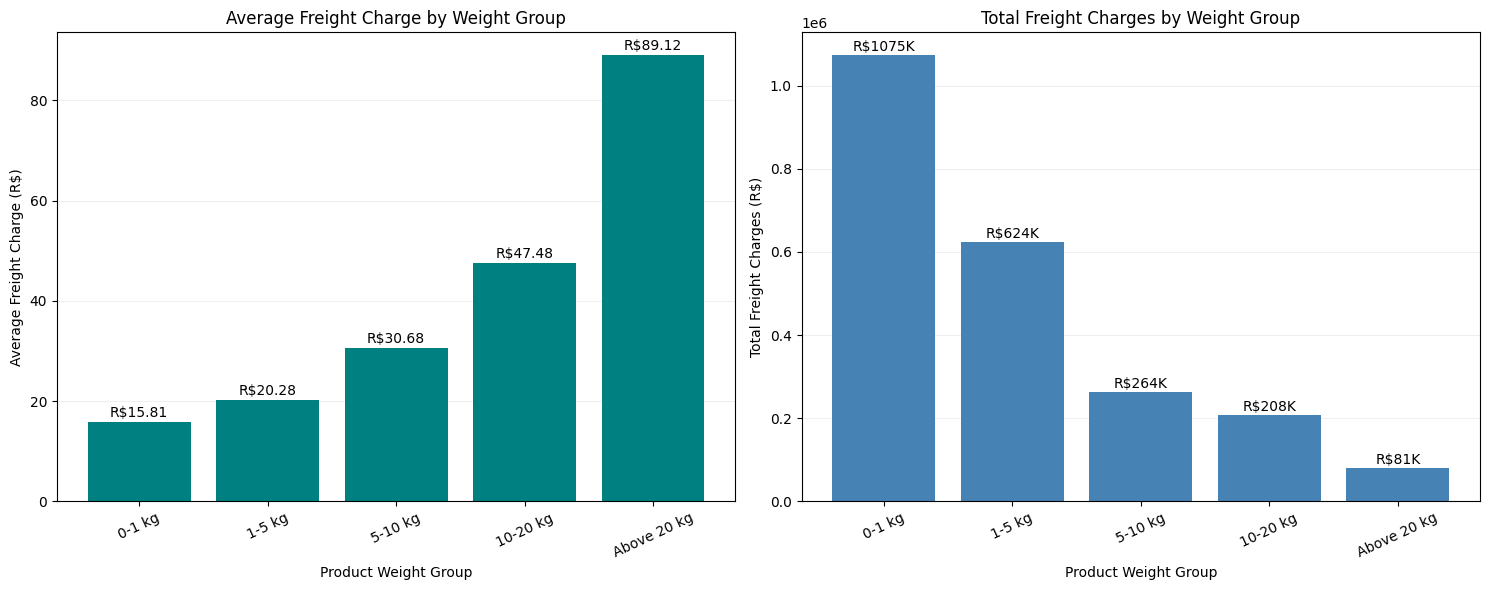

In [53]:

# STEP 30: Freight Charges by Product Weight Group

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Chart 1: Average Freight Charges
bars1 = axes[0].bar(
    weight_group_analysis['weight_group'].astype(str),
    weight_group_analysis['avg_freight'],
    color='teal'
)

axes[0].set_title('Average Freight Charge by Weight Group')
axes[0].set_xlabel('Product Weight Group')
axes[0].set_ylabel('Average Freight Charge (R$)')

for bar in bars1:
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f'R${bar.get_height():.2f}',
        ha='center'
    )

# Chart 2: Total Freight Charges
bars2 = axes[1].bar(
    weight_group_analysis['weight_group'].astype(str),
    weight_group_analysis['total_freight'],
    color='steelblue'
)

axes[1].set_title('Total Freight Charges by Weight Group')
axes[1].set_xlabel('Product Weight Group')
axes[1].set_ylabel('Total Freight Charges (R$)')

for bar in bars2:
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 10000,
        f'R${bar.get_height()/1000:.0f}K',
        ha='center'
    )

for ax in axes:
    ax.tick_params(axis='x', rotation=25)
    ax.grid(axis='y', alpha=0.2)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


In [54]:

# STEP 31: Monthly Freight Charge Analysis

# Combine order items with purchase dates
monthly_freight_data = order_items.merge(
    orders[['order_id', 'order_purchase_timestamp', 'order_status']],
    on='order_id',
    how='left',
    validate='many_to_one'
)

# Convert purchase dates to datetime
monthly_freight_data['order_purchase_timestamp'] = pd.to_datetime(
    monthly_freight_data['order_purchase_timestamp'],
    errors='coerce'
)

# Remove records without a valid purchase date
monthly_freight_data = monthly_freight_data.dropna(
    subset=['order_purchase_timestamp']
).copy()

# Create purchase month
monthly_freight_data['purchase_month'] = (
    monthly_freight_data['order_purchase_timestamp']
    .dt.to_period('M')
)

# Calculate monthly freight metrics
monthly_freight_analysis = (
    monthly_freight_data
    .groupby('purchase_month')
    .agg(
        total_items=('freight_value', 'size'),
        total_freight=('freight_value', 'sum'),
        avg_freight=('freight_value', 'mean'),
        total_product_value=('price', 'sum')
    )
    .reset_index()
)

# Calculate monthly freight-to-product ratio
monthly_freight_analysis['freight_ratio_pct'] = (
    monthly_freight_analysis['total_freight']
    / monthly_freight_analysis['total_product_value']
    * 100
)

# Round results
monthly_freight_analysis[
    ['total_freight', 'avg_freight',
     'total_product_value', 'freight_ratio_pct']
] = monthly_freight_analysis[
    ['total_freight', 'avg_freight',
     'total_product_value', 'freight_ratio_pct']
].round(2)

print("Monthly Freight Analysis:")
print(monthly_freight_analysis.to_string(index=False))


Monthly Freight Analysis:
purchase_month  total_items  total_freight  avg_freight  total_product_value  freight_ratio_pct
       2016-09            6          87.39        14.56               267.36              32.69
       2016-10          363        7301.18        20.11             49507.66              14.75
       2016-12            1           8.72         8.72                10.90              80.00
       2017-01          955       16875.62        17.67            120312.87              14.03
       2017-02         1951       38977.60        19.98            247303.02              15.76
       2017-03         3000       57704.29        19.23            374344.30              15.41
       2017-04         2684       52495.01        19.56            359927.23              14.58
       2017-05         4136       80119.81        19.37            506071.14              15.83
       2017-06         3583       69924.44        19.52            433038.60              16.15
       2017-07

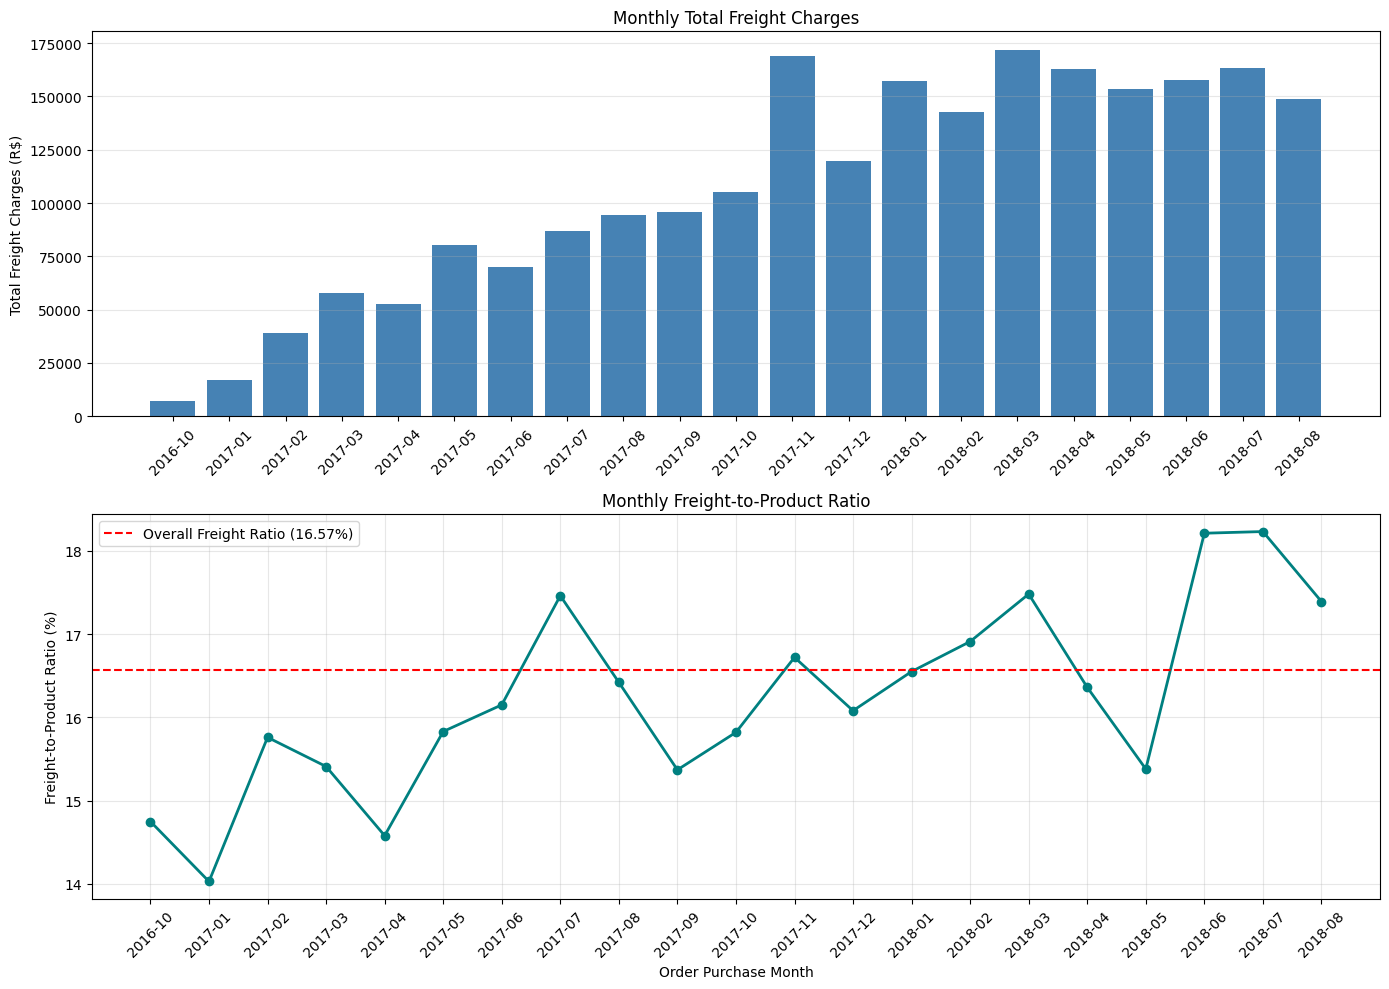

In [55]:

# STEP 32: Monthly Freight Trend Visualization

import matplotlib.pyplot as plt

# Exclude months with fewer than 100 order items
# to avoid misleading trends from very small samples
monthly_plot = monthly_freight_analysis[
    monthly_freight_analysis['total_items'] >= 100
].copy()

monthly_plot['month_label'] = (
    monthly_plot['purchase_month'].astype(str)
)

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Chart 1: Total Monthly Freight Charges
axes[0].bar(
    monthly_plot['month_label'],
    monthly_plot['total_freight'],
    color='steelblue'
)

axes[0].set_title('Monthly Total Freight Charges')
axes[0].set_ylabel('Total Freight Charges (R$)')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(axis='y', alpha=0.3)

# Chart 2: Monthly Freight-to-Product Ratio
axes[1].plot(
    monthly_plot['month_label'],
    monthly_plot['freight_ratio_pct'],
    marker='o',
    color='teal',
    linewidth=2
)

axes[1].axhline(
    y=16.57,
    color='red',
    linestyle='--',
    label='Overall Freight Ratio (16.57%)'
)

axes[1].set_title('Monthly Freight-to-Product Ratio')
axes[1].set_xlabel('Order Purchase Month')
axes[1].set_ylabel('Freight-to-Product Ratio (%)')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [56]:

# STEP 33: Freight Analysis by Product Price Range

import pandas as pd

# Create product price categories
price_freight = order_items.copy()

price_freight = price_freight[
    (price_freight['price'] > 0) &
    (price_freight['freight_value'] >= 0)
].copy()

price_freight['price_group'] = pd.cut(
    price_freight['price'],
    bins=[0, 50, 100, 200, 500, float('inf')],
    labels=[
        'R$0-50',
        'R$50-100',
        'R$100-200',
        'R$200-500',
        'Above R$500'
    ]
)

# Calculate freight metrics for each price group
price_group_analysis = (
    price_freight
    .groupby('price_group', observed=True)
    .agg(
        total_items=('price', 'size'),
        avg_product_price=('price', 'mean'),
        avg_freight=('freight_value', 'mean'),
        total_product_value=('price', 'sum'),
        total_freight=('freight_value', 'sum')
    )
    .reset_index()
)

# Calculate freight-to-product ratio
price_group_analysis['freight_ratio_pct'] = (
    price_group_analysis['total_freight'] /
    price_group_analysis['total_product_value'] * 100
)

# Round results
numeric_cols = [
    'avg_product_price',
    'avg_freight',
    'total_product_value',
    'total_freight',
    'freight_ratio_pct'
]

price_group_analysis[numeric_cols] = (
    price_group_analysis[numeric_cols].round(2)
)

print("Freight Analysis by Product Price Group:")
print(price_group_analysis.to_string(index=False))


Freight Analysis by Product Price Group:
price_group  total_items  avg_product_price  avg_freight  total_product_value  total_freight  freight_ratio_pct
     R$0-50        39317              31.44        14.77           1236117.10      580519.18              46.96
   R$50-100        33020              75.14        17.88           2480995.76      590392.04              23.80
  R$100-200        26939             143.63        23.11           3869293.99      622602.75              16.09
  R$200-500        10158             297.60        30.07           3022995.27      305500.10              10.11
Above R$500         3216             927.31        47.54           2982241.58      152895.47               5.13


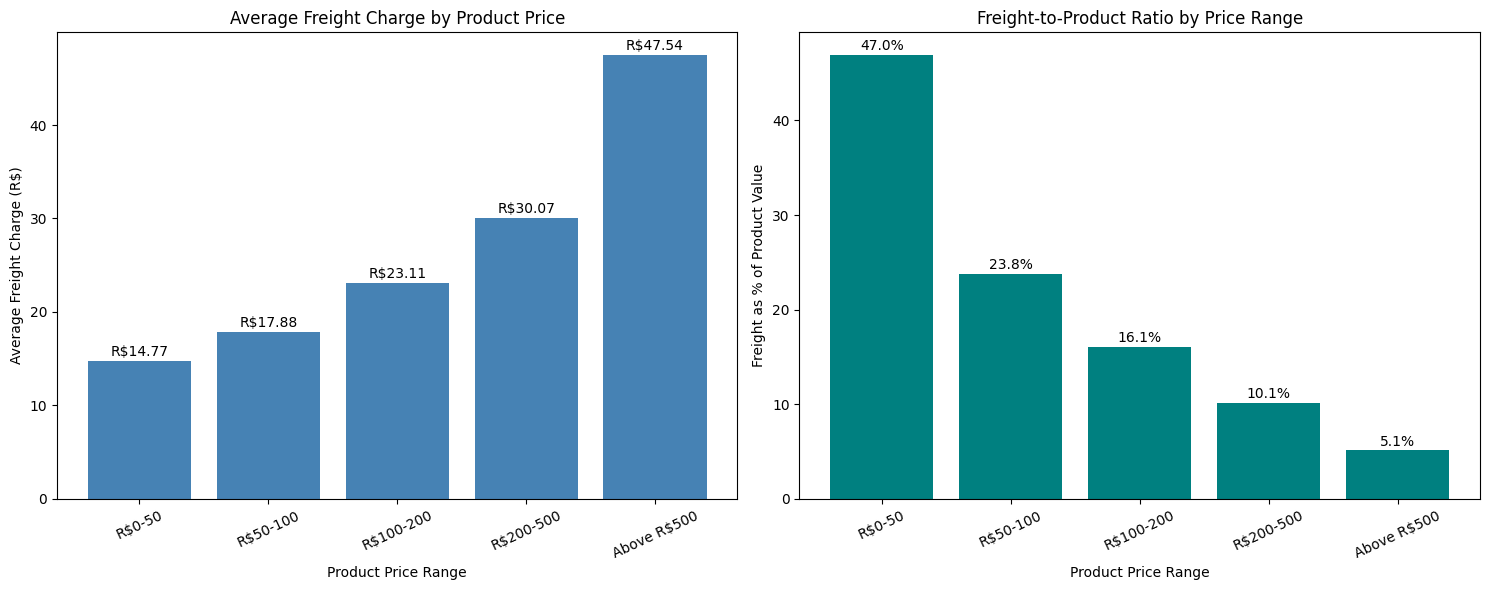

In [57]:

# STEP 34: Visualize Freight Costs by Product Price Range

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Chart 1: Average Freight Charge
bars1 = axes[0].bar(
    price_group_analysis['price_group'].astype(str),
    price_group_analysis['avg_freight'],
    color='steelblue'
)

axes[0].set_title('Average Freight Charge by Product Price')
axes[0].set_xlabel('Product Price Range')
axes[0].set_ylabel('Average Freight Charge (R$)')
axes[0].tick_params(axis='x', rotation=25)

for bar in bars1:
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f'R${bar.get_height():.2f}',
        ha='center'
    )

# Chart 2: Freight-to-Product Ratio
bars2 = axes[1].bar(
    price_group_analysis['price_group'].astype(str),
    price_group_analysis['freight_ratio_pct'],
    color='teal'
)

axes[1].set_title('Freight-to-Product Ratio by Price Range')
axes[1].set_xlabel('Product Price Range')
axes[1].set_ylabel('Freight as % of Product Value')
axes[1].tick_params(axis='x', rotation=25)

for bar in bars2:
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f'{bar.get_height():.1f}%',
        ha='center'
    )

plt.tight_layout()
plt.show()


Items analyzed: 112650
Price-Freight Correlation: 0.414


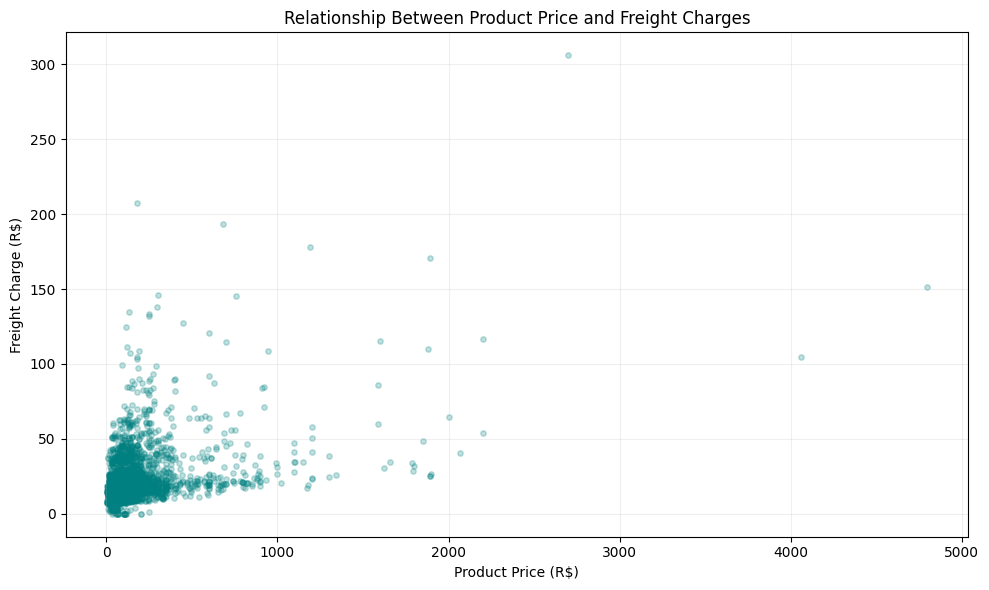

In [58]:

# STEP 35: Product Price vs Freight Charge

import matplotlib.pyplot as plt
import numpy as np

# Use order item data with valid prices and freight charges
price_freight = order_items[
    (order_items['price'] > 0) &
    (order_items['freight_value'] >= 0)
].copy()

# Calculate correlation
correlation = price_freight['price'].corr(
    price_freight['freight_value']
)

print("Items analyzed:", len(price_freight))
print(f"Price-Freight Correlation: {correlation:.3f}")

# Sample points to make the chart easier to read
sample = price_freight.sample(
    n=min(5000, len(price_freight)),
    random_state=42
)

plt.figure(figsize=(10, 6))

plt.scatter(
    sample['price'],
    sample['freight_value'],
    alpha=0.25,
    color='teal',
    s=15
)

plt.title('Relationship Between Product Price and Freight Charges')
plt.xlabel('Product Price (R$)')
plt.ylabel('Freight Charge (R$)')
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()


Items analyzed: 112624
Product Price vs Freight: 0.414
Product Weight vs Freight: 0.610


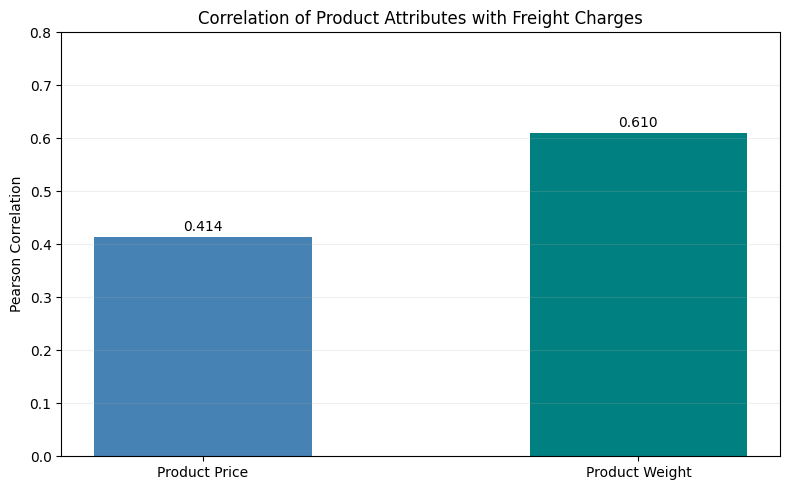

In [59]:

# STEP 36: Compare Freight Cost Drivers

import pandas as pd
import matplotlib.pyplot as plt

# Merge order items with product information
freight_drivers = order_items.merge(
    products[['product_id', 'product_weight_g']],
    on='product_id',
    how='left',
    validate='many_to_one'
)

# Convert weight from grams to kilograms
freight_drivers['weight_kg'] = (
    freight_drivers['product_weight_g'] / 1000
)

# Keep valid observations
freight_drivers = freight_drivers[
    (freight_drivers['price'] > 0) &
    (freight_drivers['freight_value'] >= 0) &
    (freight_drivers['weight_kg'] > 0)
].copy()

# Calculate correlations on the same observations
price_corr = freight_drivers['price'].corr(
    freight_drivers['freight_value']
)

weight_corr = freight_drivers['weight_kg'].corr(
    freight_drivers['freight_value']
)

print("Items analyzed:", len(freight_drivers))
print(f"Product Price vs Freight: {price_corr:.3f}")
print(f"Product Weight vs Freight: {weight_corr:.3f}")

# Create comparison chart
factors = ['Product Price', 'Product Weight']
correlations = [price_corr, weight_corr]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    factors,
    correlations,
    color=['steelblue', 'teal'],
    width=0.5
)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f'{bar.get_height():.3f}',
        ha='center'
    )

plt.title('Correlation of Product Attributes with Freight Charges')
plt.ylabel('Pearson Correlation')
plt.ylim(0, 0.8)
plt.grid(axis='y', alpha=0.2)

plt.tight_layout()
plt.show()


Items analyzed: 112632
Product Volume vs Freight Correlation: 0.587


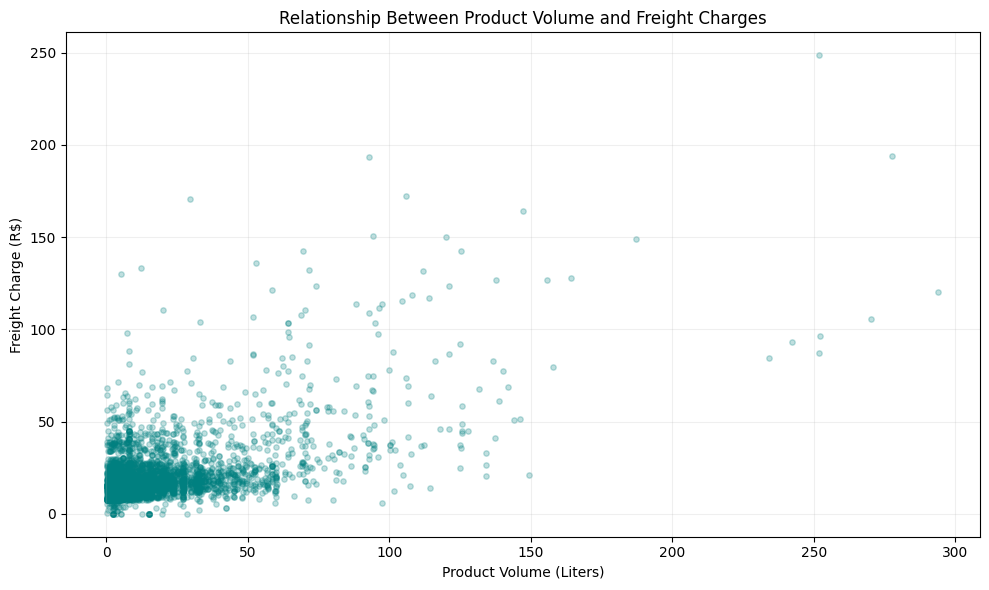

In [60]:

# STEP 37: Product Volume vs Freight Charges

import pandas as pd
import matplotlib.pyplot as plt

# Merge order items with product dimensions
volume_analysis = order_items.merge(
    products[[
        'product_id',
        'product_length_cm',
        'product_height_cm',
        'product_width_cm'
    ]],
    on='product_id',
    how='left',
    validate='many_to_one'
)

# Calculate product volume in cubic centimeters
volume_analysis['volume_cm3'] = (
    volume_analysis['product_length_cm'] *
    volume_analysis['product_height_cm'] *
    volume_analysis['product_width_cm']
)

# Keep valid records
volume_analysis = volume_analysis[
    (volume_analysis['volume_cm3'] > 0) &
    (volume_analysis['freight_value'] >= 0)
].copy()

# Calculate correlation
volume_corr = volume_analysis['volume_cm3'].corr(
    volume_analysis['freight_value']
)

print("Items analyzed:", len(volume_analysis))
print(f"Product Volume vs Freight Correlation: {volume_corr:.3f}")

# Use a sample for visualization
sample = volume_analysis.sample(
    n=min(5000, len(volume_analysis)),
    random_state=42
)

plt.figure(figsize=(10, 6))

plt.scatter(
    sample['volume_cm3'] / 1000,
    sample['freight_value'],
    alpha=0.25,
    color='teal',
    s=15
)

plt.title('Relationship Between Product Volume and Freight Charges')
plt.xlabel('Product Volume (Liters)')
plt.ylabel('Freight Charge (R$)')
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()


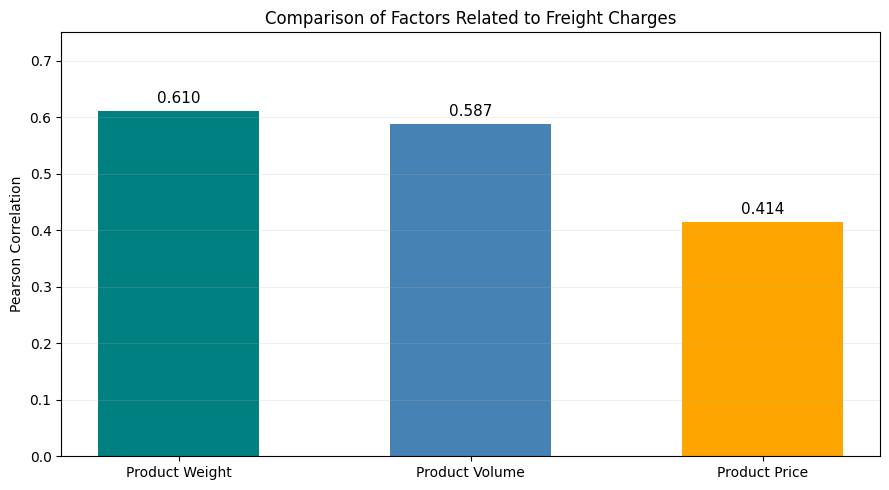

In [61]:

# STEP 38: Compare All Three Freight Cost Factors

import matplotlib.pyplot as plt

factors = [
    'Product Weight',
    'Product Volume',
    'Product Price'
]

correlations = [
    weight_corr,
    volume_corr,
    price_corr
]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    factors,
    correlations,
    color=['teal', 'steelblue', 'orange'],
    width=0.55
)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.015,
        f'{bar.get_height():.3f}',
        ha='center',
        fontsize=11
    )

plt.title('Comparison of Factors Related to Freight Charges')
plt.ylabel('Pearson Correlation')
plt.ylim(0, 0.75)
plt.grid(axis='y', alpha=0.2)

plt.tight_layout()
plt.show()


In [62]:

# STEP 39: Final Supply Chain KPI Summary

import pandas as pd

kpi_summary = pd.DataFrame({
    'KPI': [
        'Total Orders',
        'Valid Delivered Orders',
        'Average Delivery Time (Days)',
        'On-Time Delivery Rate (%)',
        'Late Delivery Rate (%)',
        'Average Delay for Late Orders (Days)',
        'Total Order Items',
        'Total Product Value (R$)',
        'Total Freight Charges (R$)',
        'Freight-to-Product Ratio (%)',
        'Late Carrier Handoff Rate (%)',
        'Weight-Freight Correlation',
        'Volume-Freight Correlation',
        'Price-Freight Correlation'
    ],
    'Value': [
        len(orders),
        len(valid_deliveries),
        round(average_delivery_time, 2),
        round(on_time_rate, 2),
        round(late_rate, 2),
        round(average_delay, 2),
        len(order_items),
        round(order_items['price'].sum(), 2),
        round(order_items['freight_value'].sum(), 2),
        round(
            order_items['freight_value'].sum() /
            order_items['price'].sum() * 100, 2
        ),
        5.98,
        round(weight_corr, 3),
        round(volume_corr, 3),
        round(price_corr, 3)
    ]
})

print("FINAL SUPPLY CHAIN KPI SUMMARY")
display(kpi_summary)


FINAL SUPPLY CHAIN KPI SUMMARY


,KPI,Value
0,Total Orders,9.944100e+04
1,Valid Delivered Orders,9.647000e+04
2,Average Delivery Time (Days),1.256000e+01
3,On-Time Delivery Rate (%),9.323000e+01
4,Late Delivery Rate (%),6.770000e+00
5,Average Delay for Late Orders (Days),1.062000e+01
6,Total Order Items,1.126500e+05
7,Total Product Value (R$),1.359164e+07
8,Total Freight Charges (R$),2.251910e+06
9,Freight-to-Product Ratio (%),1.657000e+01


In [63]:

# STEP 40: Format and Export KPI Summary

# Create a copy for display
kpi_display = kpi_summary.copy()

# Format values without scientific notation
kpi_display['Value'] = kpi_display['Value'].map(
    lambda x: f'{x:,.3f}'.rstrip('0').rstrip('.')
)

print("FINAL SUPPLY CHAIN KPI SUMMARY")
display(kpi_display)

# Save original numeric values to CSV
kpi_summary.to_csv(
    '/content/supply_chain_kpi_summary.csv',
    index=False
)

print("KPI summary saved successfully!")


FINAL SUPPLY CHAIN KPI SUMMARY


,KPI,Value
0,Total Orders,"99,441"
1,Valid Delivered Orders,"96,470"
2,Average Delivery Time (Days),12.56
3,On-Time Delivery Rate (%),93.23
4,Late Delivery Rate (%),6.77
5,Average Delay for Late Orders (Days),10.62
6,Total Order Items,"112,650"
7,Total Product Value (R$),"13,591,643.7"
8,Total Freight Charges (R$),"2,251,909.54"
9,Freight-to-Product Ratio (%),16.57


KPI summary saved successfully!


In [64]:

# STEP 42: Save Remaining Supply Chain Charts

import matplotlib.pyplot as plt
import os

os.makedirs('/content/charts', exist_ok=True)

# 1. Freight by Product Price Group
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

groups = price_group_analysis['price_group'].astype(str)

axes[0].bar(groups, price_group_analysis['avg_freight'])
axes[0].set_title('Average Freight Charge by Product Price')
axes[0].set_ylabel('Average Freight (R$)')
axes[0].tick_params(axis='x', rotation=25)

axes[1].bar(groups, price_group_analysis['freight_ratio_pct'])
axes[1].set_title('Freight-to-Product Ratio by Price Range')
axes[1].set_ylabel('Freight as % of Product Value')
axes[1].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.savefig('/content/charts/freight_by_price_group.png', dpi=300, bbox_inches='tight')
plt.close()

# 2. Product Price vs Freight
plt.figure(figsize=(10, 6))
plt.scatter(sample['price'], sample['freight_value'], alpha=0.25)
plt.title('Product Price vs Freight Charges')
plt.xlabel('Product Price (R$)')
plt.ylabel('Freight (R$)')
plt.tight_layout()
plt.savefig('/content/charts/price_vs_freight.png', dpi=300, bbox_inches='tight')
plt.close()

# 3. Product Volume vs Freight
plt.figure(figsize=(10, 6))
plt.scatter(
    volume_analysis['volume_cm3'].sample(5000, random_state=42) / 1000,
    volume_analysis['freight_value'].loc[
        volume_analysis['volume_cm3'].sample(5000, random_state=42).index
    ],
    alpha=0.25
)
plt.title('Product Volume vs Freight Charges')
plt.xlabel('Volume (Liters)')
plt.ylabel('Freight (R$)')
plt.tight_layout()
plt.savefig('/content/charts/volume_vs_freight.png', dpi=300, bbox_inches='tight')
plt.close()

# 4. Freight Cost Factor Comparison
plt.figure(figsize=(9, 5))
plt.bar(
    ['Product Weight', 'Product Volume', 'Product Price'],
    [weight_corr, volume_corr, price_corr]
)
plt.title('Factors Related to Freight Charges')
plt.ylabel('Pearson Correlation')
plt.tight_layout()
plt.savefig('/content/charts/freight_factor_comparison.png', dpi=300, bbox_inches='tight')
plt.close()

print("Four charts saved successfully!")
print(os.listdir('/content/charts'))


Four charts saved successfully!
['freight_factor_comparison.png', 'volume_vs_freight.png', 'freight_by_price_group.png', 'price_vs_freight.png']
